# Исследование рынка общественного питания Москвы

## 0.1 Цели и задачи проекта

**Цель проекта** — провести исследовательский анализ рынка общественного питания Москвы, чтобы помочь инвесторам фонда Shut Up and Take My Money выбрать подходящее место для открытия нового заведения (кафе, ресторана или бара).

**Задачи проекта:**
- Загрузить данные и познакомиться с их содержимым.
- Провести предобработку данных.
- Провести исследовательский анализ данных:
  1. изучить распределение заведений по категориям и районам;
  2. исследовать соотношение сетевых и несетевых заведений;
  3. изучить количество посадочных мест и выявить выбросы;
  4. проанализировать рейтинги заведений и их взаимосвязи с другими признаками;
  5. найти топ-15 популярных сетей Москвы;
  6. изучить вариацию среднего чека в зависимости от района.
- Сформулировать итоговый вывод и рекомендации для заказчика.

## 0.2 Описание данных

Данные основаны на информации сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Информация носит исключительно справочный характер.

**Файл `rest_info.csv` — информация о заведениях:**

- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение;
- `category` — категория заведения (например, «кафе», «пиццерия», «кофейня»);
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- `chain` — является ли заведение сетевым: `0` — нет, `1` — да (для маленьких сетей возможны ошибки);
- `seats` — количество посадочных мест.

**Файл `rest_price.csv` — информация о среднем чеке:**

- `price` — категория цен в заведении (например, «средние», «ниже среднего», «выше среднего»);
- `avg_bill` — средняя стоимость заказа в виде диапазона (например, «Средний счёт: 1000–1500 ₽», «Цена чашки капучино: 130–220 ₽»);
- `middle_avg_bill` — числовая оценка среднего чека (только для строк, начинающихся с «Средний счёт»);
- `middle_coffee_cup` — числовая оценка цены чашки капучино (только для строк, начинающихся с «Цена одной чашки капучино»).

## 0.3 Содержимое проекта

**Шаг 1. Загрузка данных и знакомство с ними**
- Загрузить датасеты `rest_info.csv` и `rest_price.csv`
- Изучить общую информацию о данных
- Проверить соответствие данных описанию, пропуски и типы данных
- Объединить датасеты в один

**Шаг 2. Предобработка данных**
- Привести типы данных к корректным
- Изучить и обработать пропущенные значения
- Проверить данные на явные и неявные дубликаты
- Создать столбец `is_24_7` (работа 24/7)

**Шаг 3. Исследовательский анализ данных**
- Категории заведений и их количество
- Распределение заведений по административным районам
- Сетевые и несетевые заведения
- Количество посадочных мест и выбросы
- Рейтинги заведений и их корреляции
- Топ-15 популярных сетей Москвы
- Средний чек в зависимости от района

**Шаг 4. Итоговый вывод и рекомендации**

# 1. Загрузка данных и знакомство с ними

Начнём с загрузки данных и знакомства с их структурой. На этом этапе важно понять объём данных, соответствие описанию, наличие пропусков и корректность типов — это определит дальнейшие шаги предобработки.

In [303]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from phik import phik_matrix

sns.set_theme(style="ticks")

In [304]:
read_info = pd.read_csv('https://code.s3.yandex.net/datasets/rest_info.csv')
read_price = pd.read_csv('https://code.s3.yandex.net/datasets/rest_price.csv')

In [305]:
display(read_info.head())
display(read_info.tail())
print(read_info.info())


,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


,id,name,category,address,district,hours,rating,chain,seats
8401,0342ad1a45ed41ba89dcba246a8267e5,Суши Мания,кафе,"Москва, Профсоюзная улица, 56",Юго-Западный административный округ,"ежедневно, 09:00–02:00",4.4,0,86.0
8402,ee6bb7c3650e47bd8186fca08eda1091,Миславнес,кафе,"Москва, Пролетарский проспект, 19, корп. 1",Южный административный округ,"ежедневно, 08:00–22:00",4.8,0,150.0
8403,62e8c64d4c89467aba608e39ef87616b,Самовар,кафе,"Москва, Люблинская улица, 112А, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",3.9,0,150.0
8404,06a0db5ecd4842d48cd6350aa923e297,Чайхана Sabr,кафе,"Москва, Люблинская улица, 112А, стр. 1",Юго-Восточный административный округ,"ежедневно, круглосуточно",4.2,1,150.0
8405,9d56f8f7a7f74df1a925bc0fd2de8aae,Kebab Time,кафе,"Москва, Россошанский проезд, 6",Южный административный округ,"ежедневно, круглосуточно",3.9,0,12.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB
None


In [306]:
display(read_price.head())
print(read_price.info())

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB
None


## Первичное знакомство с данными

По результатам загрузки и изучения общей информации о датасетах можно сделать следующие наблюдения.

### Таблица с информацией о заведениях (`rest_info`)

- В таблице хранится **9 столбцов** и **8 406 строк**;
- Пропуски обнаружены в столбцах `hours` и `seats`;
- Требуется понизить размерность столбца `rating` и `chain`;
- Столбцы `seats` необходимо привести к типу `int`. При этом для `seats` стоит предварительно изучить данные: тип `float64` скорее всего избыточен для количества посадочных мест.

### Таблица с информацией о ценах (`rest_price`)

- В таблице хранится **5 столбцов** и **4 058 строк**;
- Пропуски обнаружены в столбцах `price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`;


In [307]:
df = pd.merge(read_info, read_price, on='id', how='left')

In [308]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 853.9+ KB
None


## Шаг 2. Предобработка данных 

## 2.1 Изучение корректности типов данных

In [309]:
df['rating'] = pd.to_numeric(df['rating'], downcast = 'float')
df['seats'] = pd.to_numeric(df['seats'], downcast = 'float')
df['chain'] = pd.to_numeric(df['chain'], downcast = 'integer')


In [310]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float32
 7   chain              8406 non-null   int8   
 8   seats              4795 non-null   float32
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float32(2), float64(2), int8(1), object(8)
memory usage: 730.7+ KB
None


## 2.2 Изучение пропущенных значений 

In [311]:
round(df.isna().mean()*100,2)


id                    0.00
name                  0.00
category              0.00
address               0.00
district              0.00
hours                 6.38
rating                0.00
chain                 0.00
seats                42.96
price                60.56
avg_bill             54.60
middle_avg_bill      62.54
middle_coffee_cup    93.64
dtype: float64

## Обработка пропущенных значений

По результатам объединения данных были обнаружены пропуски в нескольких столбцах. Для каждого столбца принято отдельное решение с учётом того, как он будет использоваться в дальнейшем исследовании.

### Столбец `hours`

Принято решение пропуски в столбце `hours`, заменить индикатором 'Не указанно'

### Столбец `seats`

Пропуски в столбце `seats` заполним **медианным значением по категориям**. Это обосновано тем, что в дальнейшем будут исследоваться только выбросы и аномальные значения, а медиана по категории устойчива к выбросам и лучше отражает типичное количество посадочных мест для каждого типа заведения.

### Столбцы `price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`

- Пропуски в столбце `price` можно **восстановить при помощи столбца `middle_avg_bill`** — если известен средний чек, можно определить ценовую категорию заведения.
- Столбец `avg_bill` **заполнить не получится**: пропуски возникли из-за технического сбоя либо потому, что информация не была указана на картах.
- Столбец `middle_avg_bill` зависит от `avg_bill`, поэтому пропуски в нём предлагается заполнить **значениями-индикаторами**.
- Столбец `middle_coffee_cup` отсутствует по той же причине, что и `avg_bill`, — заполнение пропусков аналогично, значениями-индикаторами.

In [312]:
display(df[['category','seats']].head())
df['seats'] = df['seats'].fillna(df.groupby('category')['seats'].transform('median'))
display(df[['category','seats']].head())

,category,seats
0,кафе,NaN
1,ресторан,4.0
2,кафе,45.0
3,кофейня,NaN
4,пиццерия,148.0


,category,seats
0,кафе,60.0
1,ресторан,4.0
2,кафе,45.0
3,кофейня,80.0
4,пиццерия,148.0


In [313]:
display(df.groupby('price')['middle_avg_bill'].agg(['min','max']))


,min,max
price,,
высокие,0.0,35000.0
выше среднего,375.0,4500.0
низкие,90.0,600.0
средние,165.0,2150.0


**Все диапазоны накладываются друг на друга, поэтому точно заменить значения нельзя, поэтому принято решение отказатся от замены на значения и просто замена значений на индикатор '-1'**

In [314]:
df['price'] = df['price'].fillna(-1)
df['middle_avg_bill'] = df['middle_avg_bill'].fillna(-1)
df['middle_coffee_cup'] = df['middle_coffee_cup'].fillna(-1)
df['hours'] = df['hours'].fillna('Не указанно')
df['avg_bill'] = df['avg_bill'].fillna('Не указанно')


In [315]:
display(df.head())

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,60.0,-1,Не указанно,-1.0,-1.0
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,-1.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,-1.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,80.0,-1,Цена чашки капучино:155–185 ₽,-1.0,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,-1.0


**После всех преобразования в данных не осталось пропусков**

## 2.3 Изучение явных и не явных дубликатов 

In [316]:
df.duplicated().sum()

0

In [317]:
def dupl(name):
    print(f'Кол-во дупликатов до и после обработки по столбцу: {name}')
    print(df[name].nunique())
    df[name] = df[name].str.lower()
    print(df[name].nunique())
    print('\n')

In [318]:
dupl('name')
dupl('category')
dupl('district')
dupl('address')

Кол-во дупликатов до и после обработки по столбцу: name
5614
5512


Кол-во дупликатов до и после обработки по столбцу: category
8
8


Кол-во дупликатов до и после обработки по столбцу: district
9
9


Кол-во дупликатов до и после обработки по столбцу: address
5753
5752




In [319]:
print(df['category'].unique())
print('\n')
print(df['district'].unique())
print('\n')
print(df['name'].unique())
print('\n')
print(df['price'].unique())

['кафе' 'ресторан' 'кофейня' 'пиццерия' 'бар,паб' 'быстрое питание'
 'булочная' 'столовая']


['северный административный округ'
 'северо-восточный административный округ'
 'северо-западный административный округ'
 'западный административный округ' 'центральный административный округ'
 'восточный административный округ' 'юго-восточный административный округ'
 'южный административный округ' 'юго-западный административный округ']


['wowфли' 'четыре комнаты' 'хазри' ... 'миславнес' 'самовар' 'kebab time']


[-1 'выше среднего' 'средние' 'высокие' 'низкие']


**Были убранные явные и неявные дупликаты**

## 2.3 Создание столбца is_24_7(заведние работает круглосуточной)

In [320]:
df['is_24_7'] = (df['hours'] == 'ежедневно, круглосуточно')
display(df.head(5))

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,wowфли,кафе,"москва, улица дыбенко, 7/1",северный административный округ,"ежедневно, 10:00–22:00",5.0,0,60.0,-1,Не указанно,-1.0,-1.0,False
1,045780ada3474c57a2112e505d74b633,четыре комнаты,ресторан,"москва, улица дыбенко, 36, корп. 1",северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,-1.0,False
2,1070b6b59144425896c65889347fcff6,хазри,кафе,"москва, клязьминская улица, 15",северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,-1.0,False
3,03ac7cd772104f65b58b349dc59f03ee,dormouse coffee shop,кофейня,"москва, улица маршала федоренко, 12",северный административный округ,"ежедневно, 09:00–22:00",5.0,0,80.0,-1,Цена чашки капучино:155–185 ₽,-1.0,170.0,False
4,a163aada139c4c7f87b0b1c0b466a50f,иль марко,пиццерия,"москва, правобережная улица, 1б",северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,-1.0,False


## Результаты предобработки данных

В ходе предобработки данных были выполнены следующие действия:

- **Понижена размерность числовых столбцов.** Для столбцов `rating`, `chain` и `seats` уменьшена разрядность — это снижает занимаемую память и не влияет на точность анализа.

- **Обработаны пропуски в столбце `hours`.** Пропуски заменены на индикатор `'Не указано'`

- **Обработаны пропуски в столбце `seats`.** Пропуски заполнены **медианным значением по каждой категории** заведения. Медиана устойчива к выбросам и лучше отражает типичное количество посадочных мест для каждого типа общепита.

- **Обработаны пропуски в ценовых столбцах** `price`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`. Пропуски заменены на **значения-индикаторы** `'-1'` (для числовых) или `'Не указаны'` (для категориальных) — это позволяет явно отделить заведения без информации о ценах и не искажать статистику.

## Шаг 3. Исследовательский анализ данных

## 3.1 Категории заведений

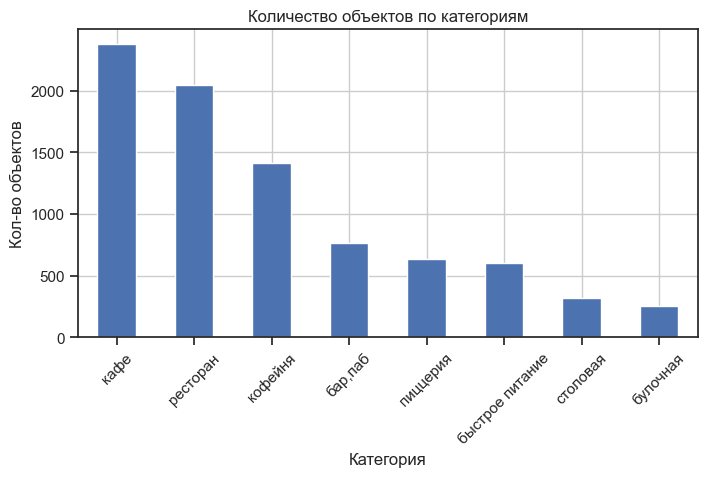

In [321]:
 

plt.figure(figsize=(8, 4))

df['category'].value_counts().plot(
    kind='bar',
    legend=False,
    rot = 45,
    title='Количество объектов по категориям'
)

plt.grid()
plt.xlabel('Категория')
plt.ylabel('Кол-во объектов')
plt.show()


**Вывод:** рынок Москвы смещён в сторону кафе и ресторанов; кофейни замыкают тройку лидеров, остальные категории представлены заметно слабее.

## 3.2 Административные районы Москвы

In [322]:
df['addis'] = df['district'].str.replace(' административный округ','')

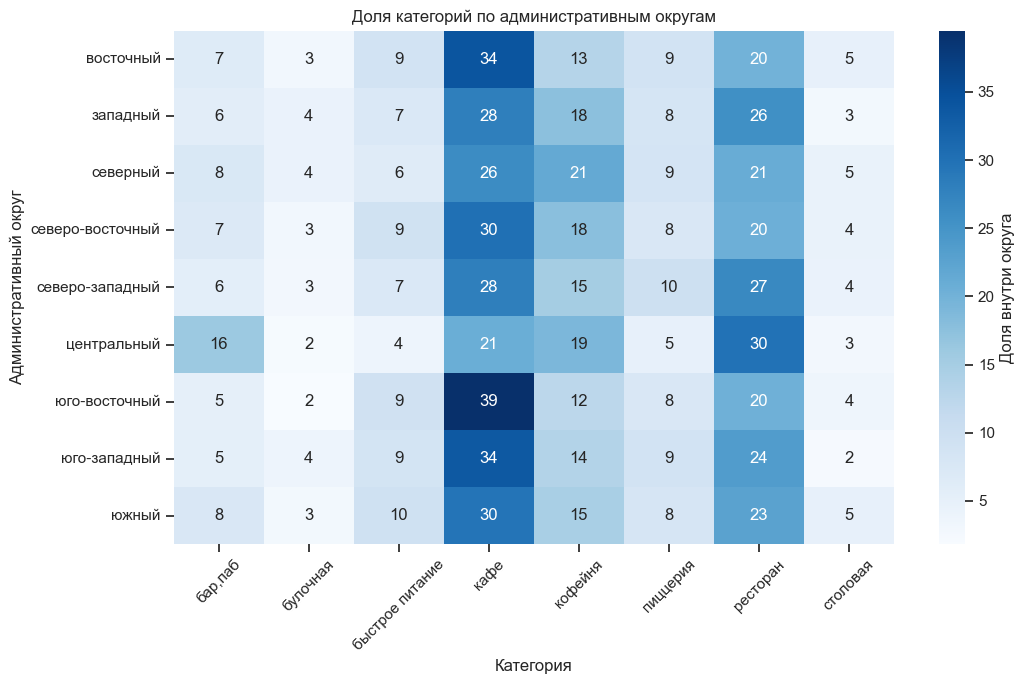

In [323]:

pivot = pd.crosstab(df['addis'], df['category'], normalize='index') * 100

plt.figure(figsize=(11, 7))

sns.heatmap(pivot, 
            cmap='Blues', 
            annot=True, 
            fmt='.0f',
            cbar_kws={'label': 'Доля внутри округа'}
            )

plt.title('Доля категорий по административным округам')
plt.xlabel('Категория')
plt.ylabel('Административный округ')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

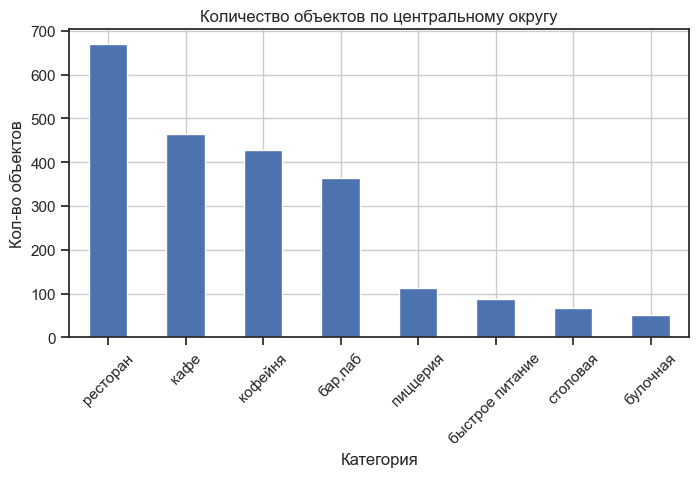

In [324]:
plt.figure(figsize=(8, 4))

dfnew = df[df['addis'] == 'центральный']

dfnew['category'].value_counts().plot(
    kind='bar',
    legend=False,
    rot = 45,
    title='Количество объектов по центральному округу'
)

plt.grid()
plt.xlabel('Категория')
plt.ylabel('Кол-во объектов')
plt.show()

### Вывод по тепловой карте

Анализ тепловой карты показывает, что основную долю заведений общественного питания в Москве занимают **кафе** и **рестораны**.

- Наибольшая концентрация **кафе** наблюдается в **Юго-Восточном**, **Восточном** и **Юго-Западном** административных округах;
- Наибольшая доля **ресторанов** сосредоточена в **Центральном**, **Западном** и **Северо-Западном** округах;
- В **Центральном административном округе** лидирующие позиции по количеству заведений занимают **рестораны**, **кафе**, **кофейни**, а также **бары и пабы**.

## 3.3 Соотношения сетевых и не сетевых заведений

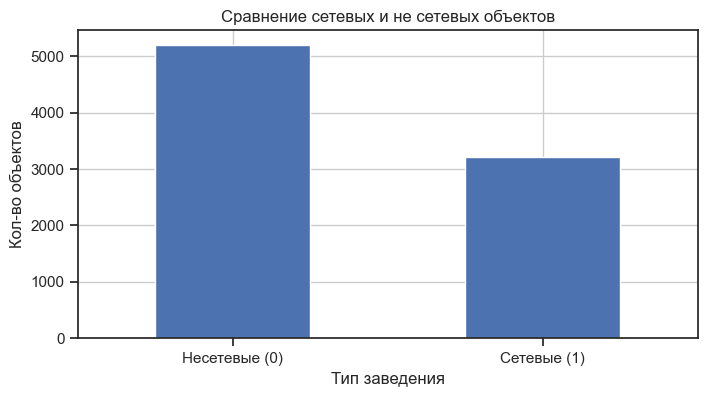

chain
0    5201
1    3205
Name: category, dtype: int64

In [325]:
plt.figure(figsize=(8, 4))


df.groupby('chain')['category'].count().plot(
    kind='bar',
    legend=False,
    rot = 0,
    title='Сравнение сетевых и не сетевых объектов'
)

plt.grid()
plt.xlabel('Тип заведения')
plt.ylabel('Кол-во объектов')
plt.xticks(ticks=[0,1], labels=['Несетевые (0)', 'Сетевые (1)'])
plt.show()

display(df.groupby('chain')['category'].count())

In [326]:
pivot_chain = df.groupby(['category', 'chain']).size().unstack()
display(pivot_chain.sort_values(by=1, ascending=False))

chain,0,1
category,,
кафе,1599,779
ресторан,1313,730
кофейня,693,720
пиццерия,303,330
быстрое питание,371,232
"бар,паб",596,169
булочная,99,157
столовая,227,88


In [327]:
pivot_chain = round(df.groupby('category')['chain'].mean().sort_values(ascending=False),2)
display(pivot_chain)

category
булочная           0.61
пиццерия           0.52
кофейня            0.51
быстрое питание    0.38
ресторан           0.36
кафе               0.33
столовая           0.28
бар,паб            0.22
Name: chain, dtype: float64

### Вывод по сетевым и несетевым заведениям

По графику видно, что **несетевых заведений значительно больше**, чем сетевых, — разница составляет почти **2 000 заведений**.

Среди сетевых заведений **наибольшее количество** приходится на **кафе**. Однако если смотреть на **долю сетевых внутри категории**, то чаще всего сетевыми оказываются **булочные**: среди всех булочных **61%** являются сетевыми.

## 3.4 Исследование количества посадочных мест в заведениях

In [328]:
## seats
df['seats'].describe(percentiles = [0.25, 0.5, 0.75])

count    8406.000000
mean       92.560432
std        94.877747
min         0.000000
25%        55.000000
50%        75.500000
75%        86.000000
max      1288.000000
Name: seats, dtype: float64

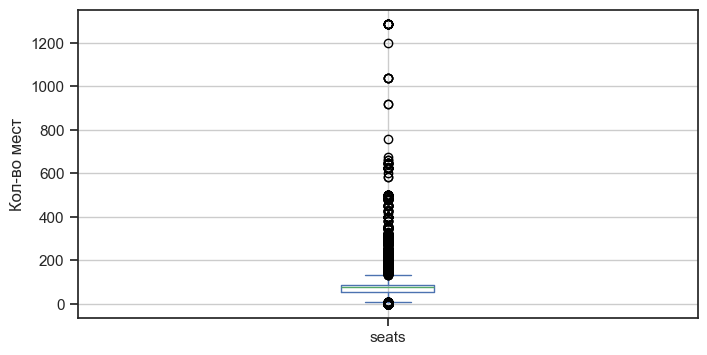

In [329]:
plt.figure(figsize=(8, 4))

df['seats'].plot(kind = 'box')

plt.grid()
plt.ylabel('Кол-во мест')
plt.show()

plt.show()

**По графику и анализу видно, что в данных присутствует достаточно много выбросов, можно предположить, что они связанны с какой-то технической ошибкой**

In [330]:
display(df[df['seats'] > 1200].head()) #Не единичный случай, и очен ьмал шанс, что в пабе будет столько мест, поэтому скорее всего это просто техничсеская ошибка

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup,is_24_7,addis
6518,fbf22d98b62a47fbb2a71be3545f16b2,delonixcafe,ресторан,"москва, проспект вернадского, 94, корп. 1",западный административный округ,"ежедневно, круглосуточно",4.1,0,1288.0,высокие,Средний счёт:1500–2000 ₽,1750.0,-1.0,True,западный
6524,c93d20f53072495c9cf2e489914cb8a5,ян примус,ресторан,"москва, проспект вернадского, 121, корп. 1",западный административный округ,"пн-чт 12:00–00:00; пт,сб 12:00–02:00; вс 12:00...",4.5,1,1288.0,выше среднего,Средний счёт:1500 ₽,1500.0,-1.0,False,западный
6574,5925d9677fe24778a27e35ccd88c0a2d,мюнгер,пиццерия,"москва, проспект вернадского, 97, корп. 1",западный административный округ,"пн-пт 08:00–21:00; сб,вс 10:00–21:00",4.8,1,1288.0,-1,Не указанно,-1.0,-1.0,False,западный
6641,0508ba663a4c42d1b5068e51afcc26ef,one price coffee,кофейня,"москва, проспект вернадского, 84, стр. 1",западный административный округ,"ежедневно, 08:30–20:00",4.3,1,1288.0,-1,Не указанно,-1.0,-1.0,False,западный
6658,19a223ff04f74af7a12bd87b77ce468b,гудбар,"бар,паб","москва, проспект вернадского, 97, корп. 1",западный административный округ,"пн-пт 11:00–23:00; сб,вс 13:00–23:00",4.1,0,1288.0,средние,Средний счёт:700 ₽,700.0,-1.0,False,западный


In [331]:
print(df.groupby('category')['seats'].agg(lambda x: x.mode().iloc[0] if not x.mode().empty else None))

category
бар,паб            82.5
булочная           50.0
быстрое питание    65.0
кафе               60.0
кофейня            80.0
пиццерия           55.0
ресторан           86.0
столовая           75.5
Name: seats, dtype: float32


### Вывод по количеству посадочных мест

По графику видно, что в столбце `seats` присутствует **значительное количество выбросов**. Они могут быть связаны как с **технической ошибкой** при сборе данных, так и с **некорректной информацией**, указанной на картах.

Для каждой категории заведений была рассчитана **мода** — наиболее типичное количество посадочных мест. По результатам анализа:

- Самым вместительным заведением оказался **«бар, паб»**. Вероятно, это связано с тем, что в таких заведениях люди могут находиться стоя, и владельцы учитывают это как отдельное место;
- Самым маловместительным заведением оказалась **булочная**.

## 3.5 Рейтинг заведений

In [332]:
mass = df.groupby('category')['rating'].mean()
mass

category
бар,паб            4.387712
булочная           4.268359
быстрое питание    4.050249
кафе               4.123886
кофейня            4.277282
пиццерия           4.301264
ресторан           4.290358
столовая           4.211429
Name: rating, dtype: float32

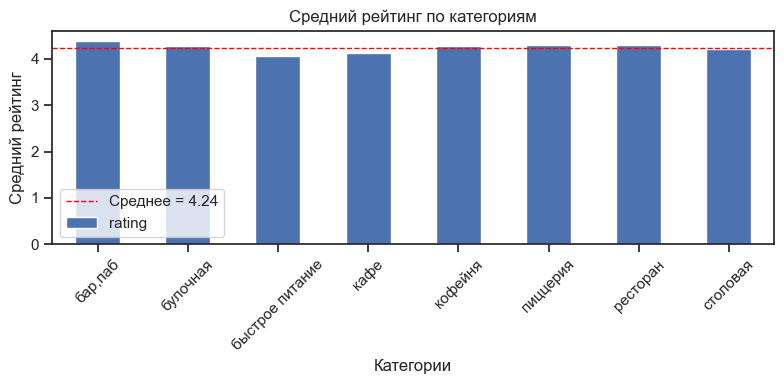

In [333]:
fig, ax = plt.subplots(figsize=(8, 4))

mass.plot(
    kind='bar',
    rot=45,
    ax=ax,                
)

ax.axhline(
    y=mass.mean(),
    color='red',
    linestyle='--',
    linewidth=1,
    label=f'Среднее = {mass.mean():.2f}',
)

ax.legend()
plt.title('Средний рейтинг по категориям')
plt.xlabel('Категории')
plt.ylabel('Средний рейтинг')
plt.tight_layout()
plt.show()

### Вывод по среднему рейтингу заведений

По графику видно, что все категории заведений находятся **примерно в одном диапазоне** значений — их средние рейтинги близки к общему среднему (около **4,24**).

Однако среди них можно выделить лидеров и аутсайдеров:
- Наименьший средний рейтинг — у категории **«быстрое питание»**;
- Наибольший средний рейтинг — у категории **«бар, паб»**.

**Главный вывод:** рейтинг заведения **слабо зависит от его категории** — разница между категориями минимальна, поэтому категория не является определяющим фактором высокой или низкой оценки.

## 3.6 Корреляция рейтинга с другими столбцами

In [338]:
correlation_matrix = df[['category', 'rating', 'district', 'chain', 'price', 'is_24_7', 'seats']].phik_matrix()
data_heatmap = correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)
display(data_heatmap)

interval columns not set, guessing: ['rating', 'chain', 'seats']


,rating
price,0.310534
category,0.198949
district,0.189389
is_24_7,0.160804
chain,0.119071
seats,0.000000


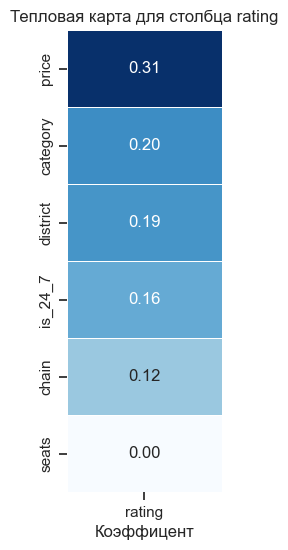

In [343]:
plt.figure(figsize=(2, 6))

sns.heatmap(data_heatmap,
            annot=True,
            fmt='.2f',
            cmap='Blues',
            linewidths=0.5,
            cbar=False
           )

plt.title('Тепловая карта для столбца rating')
plt.xlabel('Коэффицент')

plt.show()

**Вывод:** самая сильная связь с рейтингом — у ценовой категории `price`; самая слабая `seats`.


Тут я не понял как нужно проверить :((